In [1]:
%matplotlib widget
import open3d as o3d
import numpy as np
import matplotlib.pyplot as plt
import copy

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [2]:
def draw_registration_result_original_color(source, target, transformation, num_points: int = 300):
    source_temp = copy.deepcopy(source)
    source_temp.transform(transformation)

    fig = plt.figure()
    ax = fig.add_subplot(projection='3d')

    source_points = np.array(source_temp.points)
    target_points = np.array(target.points)

    # Randomly sample the points
    sampled_indices = np.random.choice(len(source_points), num_points, replace=False)
    source_points = source_points[sampled_indices]
    sampled_indices = np.random.choice(len(target_points), num_points, replace=False)
    target_points = target_points[sampled_indices]

    # Display pointclouds
    ax.scatter(source_points[:, 0], source_points[:, 1], source_points[:, 2], c='r')
    ax.scatter(target_points[:, 0], target_points[:, 1], target_points[:, 2], c='g')
    
    plt.show()

1. Load two point clouds and show initial pose


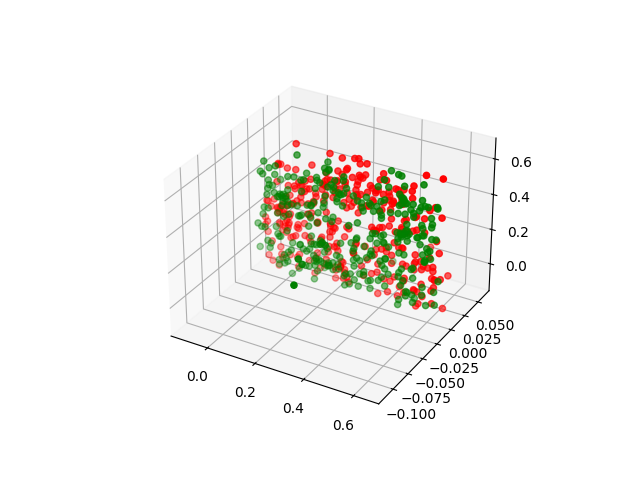

In [3]:
print("1. Load two point clouds and show initial pose")
demo_colored_icp_pcds = o3d.data.DemoColoredICPPointClouds()
source = o3d.io.read_point_cloud("/home/repos/Neo/exports/real/remove/single/tomato_soup_can/tomato_soup_can/after/nerfacto/2024-12-03_134659/point_cloud.ply")
target = o3d.io.read_point_cloud("/home/repos/Neo/exports/real/remove/single/tomato_soup_can/tomato_soup_can/before/lerf/2024-12-03_123956/point_cloud.ply")

# draw initial alignment
current_transformation = np.identity(4)
draw_registration_result_original_color(source, target, current_transformation)

3. Colored point cloud registration
[50, 0.04, 0]
3-1. Downsample with a voxel size 0.04
3-2. Estimate normal.
3-3. Applying colored point cloud registration
Final transform:
[[ 9.99974926e-01  1.38081147e-03  6.94554774e-03 -4.42950343e-03]
 [-1.37608684e-03  9.99998819e-01 -6.84971054e-04 -6.78141266e-03]
 [-6.94648535e-03  6.75396202e-04  9.99975645e-01  1.70461363e-03]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  1.00000000e+00]]
RegistrationResult with fitness=9.669118e-01, inlier_rmse=9.366325e-03, and correspondence_set size of 526
Access transformation to get result.
[30, 0.02, 1]
3-1. Downsample with a voxel size 0.02
3-2. Estimate normal.
3-3. Applying colored point cloud registration
Final transform:
[[ 9.99999562e-01 -9.16657265e-04 -1.91125566e-04 -5.20554647e-04]
 [ 9.16577252e-04  9.99999492e-01 -4.18308981e-04 -5.08700061e-03]
 [ 1.91508915e-04  4.18133617e-04  9.99999894e-01  7.06815150e-04]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  1.00000000e+00]]
Regi

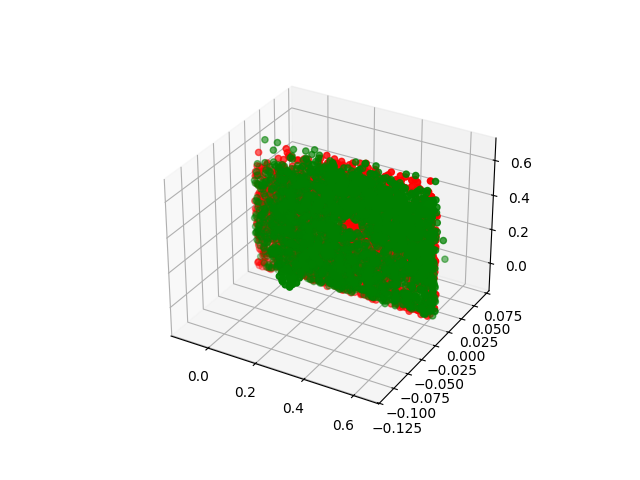

In [4]:
# colored pointcloud registration
# This is implementation of following paper
# J. Park, Q.-Y. Zhou, V. Koltun,
# Colored Point Cloud Registration Revisited, ICCV 2017
voxel_radius = [0.04, 0.02, 0.01]
max_iter = [50, 30, 14]
current_transformation = np.identity(4)
print("3. Colored point cloud registration")
for scale in range(3):
    iter = max_iter[scale]
    radius = voxel_radius[scale]
    print([iter, radius, scale])

    print("3-1. Downsample with a voxel size %.2f" % radius)
    source_down = source.voxel_down_sample(radius)
    target_down = target.voxel_down_sample(radius)

    print("3-2. Estimate normal.")
    source_down.estimate_normals(
        o3d.geometry.KDTreeSearchParamHybrid(radius=radius * 2, max_nn=30))
    target_down.estimate_normals(
        o3d.geometry.KDTreeSearchParamHybrid(radius=radius * 2, max_nn=30))

    print("3-3. Applying colored point cloud registration")
    result_icp = o3d.pipelines.registration.registration_colored_icp(
        source_down, target_down, radius, current_transformation,
        o3d.pipelines.registration.TransformationEstimationForColoredICP(),
        o3d.pipelines.registration.ICPConvergenceCriteria(relative_fitness=1e-6,
                                                          relative_rmse=1e-6,
                                                          max_iteration=iter))
    current_transformation = result_icp.transformation
    print("Final transform:")
    print(current_transformation)
    print(result_icp)
draw_registration_result_original_color(source, target,
                                        result_icp.transformation, num_points=3000)